In [1]:
import sys

print(sys.executable)
print(sys.version)

/home/bily/python/forest_harvest/.venv/bin/python
3.12.13 (main, Jun 11 2026, 04:03:26) [Clang 22.1.3 ]


In [2]:
from pystac_client import Client
import odc.stac, odc.geo.xr
import geopandas as gpd
import rasterio.features
import matplotlib.pyplot as plt
from shapely.geometry import shape


In [6]:
# Let's Load AOI and get a comparison over time to find harvests and burns
aoi = gpd.read_file(r"../data/stMary_aoi.shp")
# convert the aoi to WGS84
aoi_wgs = aoi.to_crs("EPSG:4326")
bbox = aoi_wgs.total_bounds
print(bbox)

[-114.43805411   46.2757663  -114.01293748   46.62299715]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

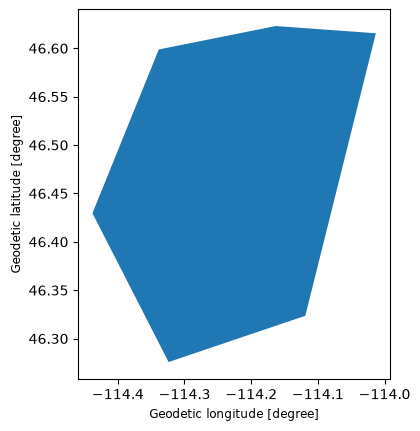

In [4]:
# This is a hand drawn aoi around St. Mary in the Bitterroot Mountains
# A burn happened here recently and we will try to detect it
aoi_wgs.plot()

In [5]:
# Search the same season in two years (the fire was in the early fall of 2024)

cat = Client.open("https://earth-search.aws.element84.com/v1")

def search(dates):
    return cat.search(collections=["sentinel-2-c1-l2a"],
                      bbox=bbox,
                      datetime=dates,
                      query={"eo:cloud_cover": {"lt": 40}}).item_collection()

# Capture most of the growing season, and try to end before smoke season
before_items = search("2024-05-15/2024-07-31")
after_items = search("2025-05-15/2025-07-31")

len(before_items), len(after_items)

/home/bily/python/forest_harvest/.venv/lib/python3.12/site-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


(37, 45)

In [6]:
# Load the bands that I am interested in
def load(items):
    return odc.stac.load(items,
                         bands=["nir", "swir22", "scl"], bbox=bbox,
                         resolution=10,
                         groupby="solar_day",
                         chunks={})

before, after = load(before_items), load(after_items)

In [7]:
# Mask clouds and get median NBR per period
BAD_FILTER = [0, 1, 2, 3, 8, 9, 10, 11] # no-data, saturated, shadow, cloud, cirrus, snow

def nbr_stack(ds):
    clear = ~ds.scl.isin(BAD_FILTER)
    nir = ds.nir.where(clear).astype("float32")
    swir = ds.swir22.where(clear).astype("float32")
    return ((nir-swir)/(nir+swir))

stack_b = nbr_stack(before).compute()
stack_a = nbr_stack(after).compute()

nbr_before = stack_b.median("time")
nbr_after = stack_a.median("time")
dnbr = nbr_before - nbr_after # positive = vegetation lost

/home/bily/python/forest_harvest/.venv/lib/python3.12/site-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Text(0.5, 1.0, 'dNBR')

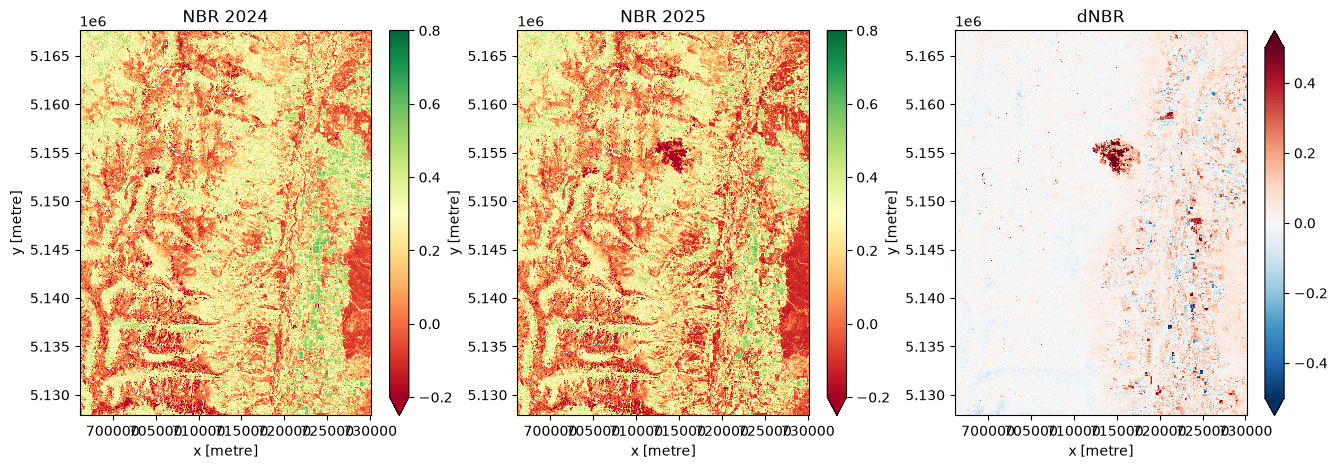

In [8]:
# Take a look at the images
fig, ax = plt.subplots(1, 3, figsize=(16,5))
nbr_before.plot(ax=ax[0], vmin=-0.2, vmax=0.8, cmap="RdYlGn"); ax[0].set_title("NBR 2024")
nbr_after.plot(ax=ax[1], vmin=-0.2, vmax=0.8, cmap="RdYlGn"); ax[1].set_title("NBR 2025")
dnbr.plot(ax=ax[2], vmin=-0.5, vmax=0.5, cmap="RdBu_r"); ax[2].set_title("dNBR")


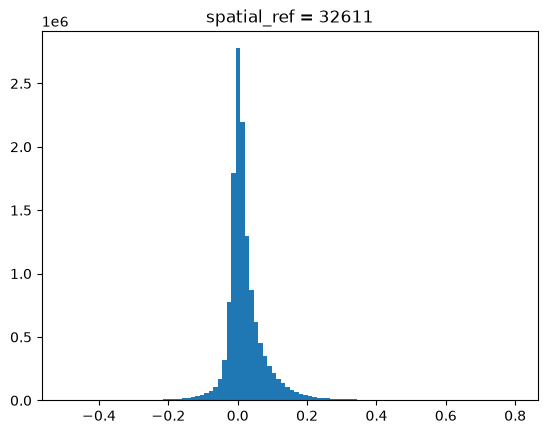

In [9]:
# explore the dNBR
dnbr.plot.hist(bins=100, range=(-0.5, 0.8));

In [10]:
# Nice! We see the fire clearly in the map and the long tail to the right confirms that the
# values are stretching towards 0.2. Let's use that as a cutoff

fire_mask = (dnbr > 0.2).values.astype("uint8")
polys = [shape(g) for g, _ in rasterio.features.shapes(fire_mask, mask=fire_mask ==1,
                                                       transform=dnbr.odc.transform)]

fire_gdf = gpd.GeoDataFrame(geometry=polys, crs=dnbr.odc.crs)
print(fire_gdf.crs) # check the crs to make sure the area filter is in the correct units
fire_gdf = fire_gdf[fire_gdf.area >= 4046.86] # filte for things >= 1 acre
fire_gdf.explore()

PROJCRS["WGS 84 / UTM zone 11N",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G1674)"],MEMBER["World Geodetic System 1984 (G1762)"],MEMBER["World Geodetic System 1984 (G2139)"],MEMBER["World Geodetic System 1984 (G2296)"],ELLIPSOID["WGS 84",6378137,298.257223563,LENGTHUNIT["metre",1]],ENSEMBLEACCURACY[2.0]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4326]],CONVERSION["UTM zone 11N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-117,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False 

In [11]:
# Let's see what happens if we determine the dNBR break based on the zscore

nb, na = stack_b.count("time"), stack_a.count("time")
se = ((stack_b.var("time", ddof=1) / nb) + (stack_a.var("time", ddof=1) / na)) ** 0.5 # use ddof=1 in case we only have one valid scene
z = (stack_b.mean("time") - stack_a.mean("time")) / se # Welch t-stat

candidate = (z >= 3) & (dnbr >= 0.05) # a little funny because z-score is built from means and dnbr is the median - but let's see

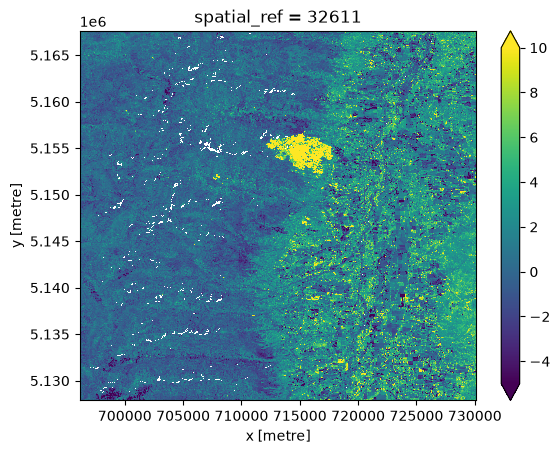

In [12]:
z.plot(vmin=-5, vmax=10)

In [15]:
z.quantile([0.01, 0.05, 0.99, 0.999]).values

array([-4.08386701, -2.00229951,  9.93586916, 33.60016662])

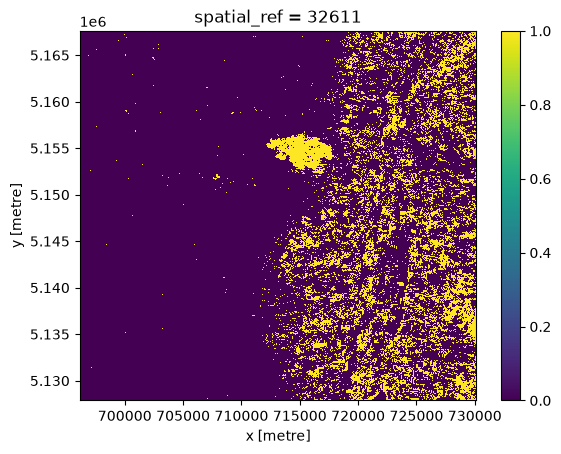

In [16]:
candidate.plot()

In [18]:
# save z as an output
import numpy as np
from pathlib import Path

output_dir = r"./outputs"

Path(output_dir).mkdir(exist_ok=True)
z_out = z.where(np.isfinite(z)).astype("float32")
z_out.odc.write_cog(f"{output_dir}/stMary_z.tif", overwrite=True)

# save fire shapefile
fire_gdf.to_file(rf"{output_dir}/fire_shapes.geojson")

Alright -
We are capturing a bunch of agricultural fields in the valley, but we are capturing the fire around St. Mary. We just need to refine the result. I think I would like to classify forest first, then use that as a filter.

Some thoughts here are to use the NLCD dataset versus trying to classify it myself at the moment. Though that would be a fun thing to do later.
